In [1]:
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#Carregar o modelo
from keras.models import load_model
#salvar/carregar arquivos em diferentes formatos
import joblib
# Gerenciamento de arquivos e modelos
import os

2026-10-18 22:32:31.198289: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-18 22:32:31.270180: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 22:32:31.870795: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 22:32:31.877228: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are us

In [2]:
diretorio = "./data/imagens de fluorescencia/save/"
os.listdir(diretorio)[:4]

['imagens_validação_10%_fluore_2026-10-18.gz',
 'lista_img_100_resized_fluorescente_cho745_2026-10-18.gz',
 'lista_img_25_resized_fluorescente_cho745_2026-10-18.gz',
 'lista_img_50_resized_fluorescente_cho745_2026-10-18.gz']

In [3]:
#Importando o modelo contendo os valores previstos para o número de células nas imagens
modelo_maior_erro = load_model(f'{diretorio}modelo_fluore_100_75_50_25_2026-10-18.keras')
modelo_maior_erro

In [4]:
X_test_maior_erro = joblib.load(f'{diretorio}imagens_validação_10%_fluore_2026-10-18.gz') #carregando arquivo
X_test_maior_erro.shape

(64, 250, 300, 3)

In [5]:
y_test_maior_erro = joblib.load(f'{diretorio}rótulos_validação_10%_fluore_2026-10-18.gz') #carregando arquivo
y_test_maior_erro.shape

(64,)

In [6]:
#ROTULOS SALVOS EM LISTA

lista_observado_maior_erro = list(y_test_maior_erro)
len(lista_observado_maior_erro)

64

In [7]:
#PREDIÇÃO SALVO EM LISTA

dados_prev = modelo_maior_erro.predict(X_test_maior_erro)
lista_previsto_maior_erro = dados_prev.flatten().tolist()
len(lista_previsto_maior_erro)

2/2 [==============================] - 1s 269ms/step


64

In [8]:
import pandas as pd
from scipy.stats.stats import pearsonr as stats

/tmp/ipykernel_4354/3864774765.py:2: DeprecationWarning: Please use `pearsonr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import pearsonr as stats


In [9]:
#DATAFRAME - ORGANIZAÇÃO DAS LISTAS
#COLUNA 1 ROTULO/ COLUNA 2 PREDITO

df_maior_erro = pd.DataFrame(zip(lista_observado_maior_erro,lista_previsto_maior_erro),
                             columns = ['Observed values','Lista preditos'])
df_maior_erro.head()

,Observed values,Lista preditos
0,202,193.292908
1,129,186.300919
2,36,89.903625
3,208,170.174469
4,144,142.211670


In [ ]:
#ARREDONDANDO O PREDITO ('lista preditos')

teste = round(df_maior_erro['Lista preditos'],2)
df_maior_erro['Predicted values'] = teste
df_maior_erro.head()

,Observed values,Lista preditos,Predicted values
0,202,193.292908,193.29
1,129,186.300919,186.30
2,36,89.903625,89.90
3,208,170.174469,170.17
4,144,142.211670,142.21


In [11]:
#REORGANIZANDO AS COLUNAS

df_maior_erro = df_maior_erro.reindex(columns=['Observed values','Predicted values','Lista preditos'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos
0,202,193.29,193.292908
1,129,186.30,186.300919
2,36,89.90,89.903625
3,208,170.17,170.174469
4,144,142.21,142.211670


In [ ]:
#BIBLIOTECA CORRELAÇÃO
from scipy.stats.stats import spearmanr as spearman #importando a biblioteca para gráfico de correlação

/tmp/ipykernel_4354/923420305.py:2: DeprecationWarning: Please use `spearmanr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import spearmanr as spearman #importando a biblioteca para gráfico de correlação


In [ ]:
from scipy import stats

col1_obt = 0 #Observed value
col2_prev = 1 #Predicted values

# Verifique se as colunas contêm apenas valores numéricos
df_maior_erro[df_maior_erro.columns[col1_obt]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col1_obt]], errors='coerce')
df_maior_erro[df_maior_erro.columns[col2_prev]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col2_prev]], errors='coerce')

# Remova as linhas com valores NaN resultantes da conversão
df_maior_erro = df_maior_erro.dropna(subset=[df_maior_erro.columns[col1_obt], df_maior_erro.columns[col2_prev]])

# Calcular a correlação
pear_pos_maior_erro = stats.pearsonr(df_maior_erro[df_maior_erro.columns[col1_obt]],
                                     df_maior_erro[df_maior_erro.columns[col2_prev]])

print(pear_pos_maior_erro)

PearsonRResult(statistic=0.9240088544698324, pvalue=1.4165572075911218e-27)


<Figure size 1500x1500 with 0 Axes>

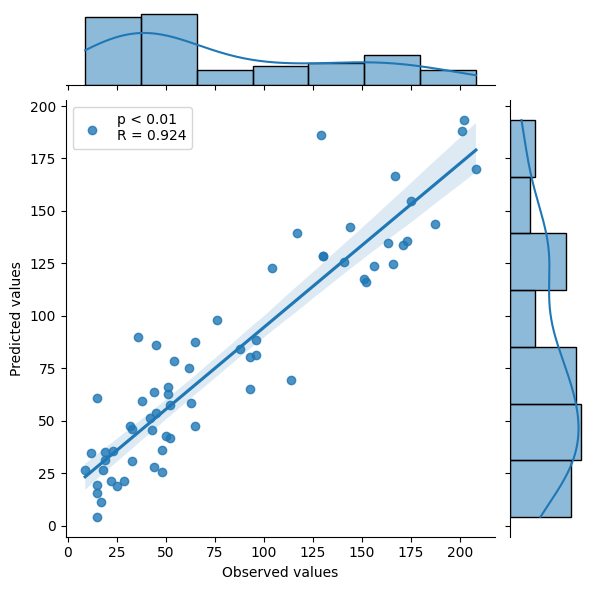

In [14]:
plt.figure(figsize=(15,15))
sns.jointplot(
    x=df_maior_erro.columns[col1_obt],
    y=df_maior_erro.columns[col2_prev],
    kind='reg',
    data=df_maior_erro#[df_maior_erro['Lista observado'] > 300]
)

if pear_pos_maior_erro[1] < 0.01:
  plt.legend(['p < ' + '0.01' + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e relse:
else:
  plt.legend(['p = ' + str(round(pear_pos_maior_erro[1],4)) + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e r